In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv


In [2]:
import os

for folder in os.listdir('/kaggle/input'):
    print("Folder:", folder)
    path = '/kaggle/input/' + folder
    print("Files:", os.listdir(path))

Folder: datasets
Files: ['batooljuaitem']


In [3]:
import os

path = '/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success'

print(os.listdir(path))

['data.csv']


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    '/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv',
    sep=';'
)

df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [5]:
# Dataset Information

print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualificati

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Percentage Distribution:
Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64


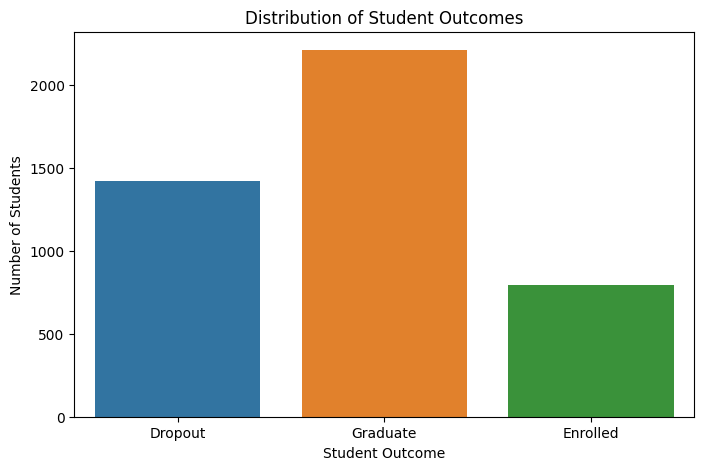

In [6]:
# Target Class Distribution

print(df['Target'].value_counts())

print("\nPercentage Distribution:")
print(df['Target'].value_counts(normalize=True) * 100)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Target', hue='Target', legend=False)

plt.title('Distribution of Student Outcomes')
plt.xlabel('Student Outcome')
plt.ylabel('Number of Students')
plt.show()

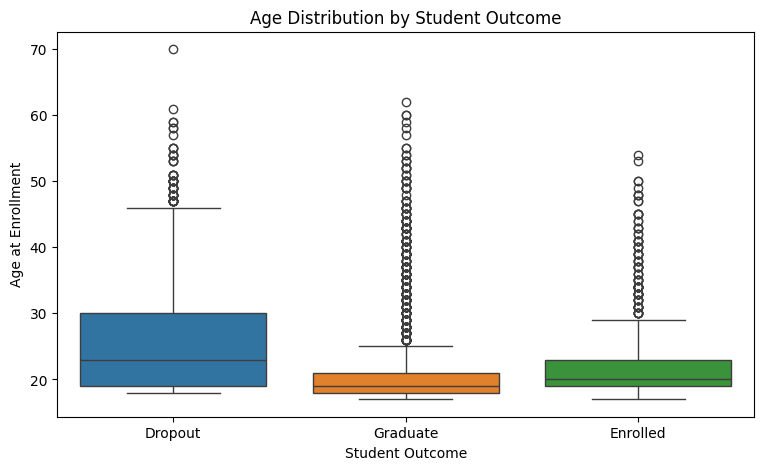

In [7]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Target',
    y='Age at enrollment',
    hue='Target',
    legend=False
)

plt.title('Age Distribution by Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('Age at Enrollment')
plt.show()

Target                Dropout   Enrolled   Graduate
Scholarship holder                                 
0                   38.706767  19.969925  41.323308
1                   12.192903  11.828935  75.978162


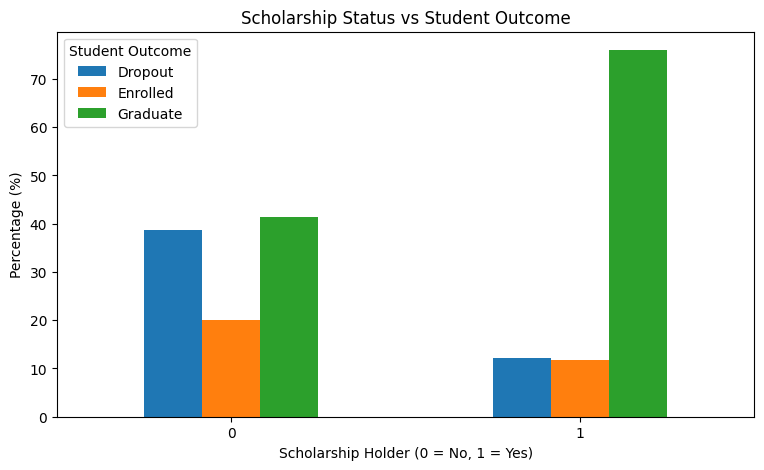

In [8]:
# Scholarship vs Student Outcome

scholarship_result = pd.crosstab(
    df['Scholarship holder'],
    df['Target'],
    normalize='index'
) * 100

print(scholarship_result)

scholarship_result.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Scholarship Status vs Student Outcome')
plt.xlabel('Scholarship Holder (0 = No, 1 = Yes)')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Student Outcome')
plt.show()

Target    Dropout   Enrolled   Graduate
Gender                                 
0       25.104603  16.980474  57.914923
1       45.051414  19.730077  35.218509


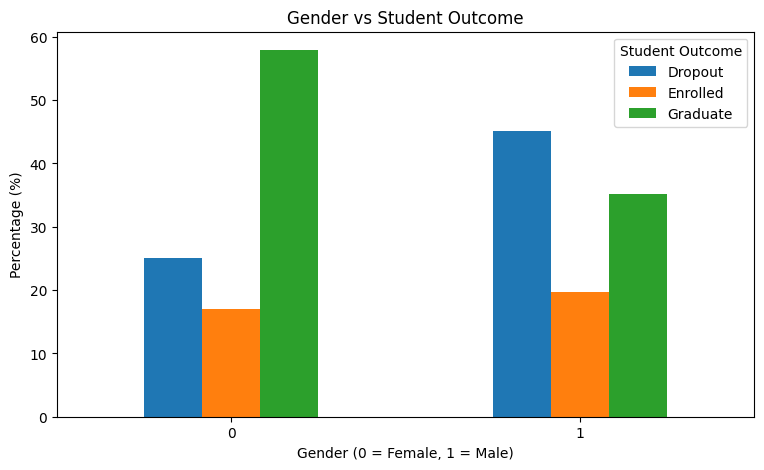

In [9]:
# ==========================================
# EDA Phase 6: Gender vs Student Outcome
# Objective: Analyze student outcomes by gender
# ==========================================

gender_result = pd.crosstab(
    df['Gender'],
    df['Target'],
    normalize='index'
) * 100

print(gender_result)

gender_result.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Gender vs Student Outcome')
plt.xlabel('Gender (0 = Female, 1 = Male)')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Student Outcome')
plt.show()

Target           Dropout   Enrolled   Graduate
Age Group                                     
20 or younger  21.246570  18.463348  60.290082
21-25          35.628019  21.980676  42.391304
26-35          57.580398  14.395100  28.024502
36+            53.061224  11.989796  34.948980


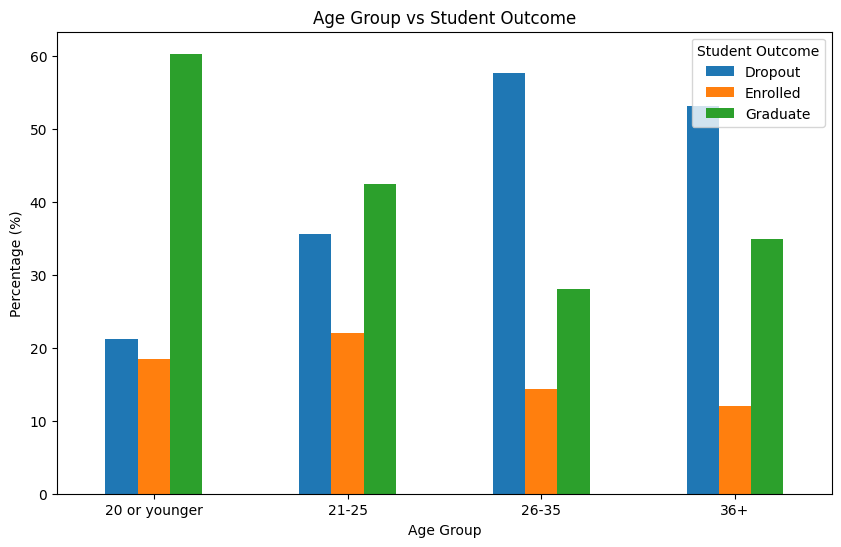

In [10]:
# ==========================================
# EDA Phase 7: Age Group vs Student Outcome
# Objective: Analyze student outcomes across age groups
# ==========================================

df['Age Group'] = pd.cut(
    df['Age at enrollment'],
    bins=[0, 20, 25, 35, 100],
    labels=['20 or younger', '21-25', '26-35', '36+']
)

age_result = pd.crosstab(
    df['Age Group'],
    df['Target'],
    normalize='index'
) * 100

print(age_result)

age_result.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Age Group vs Student Outcome')
plt.xlabel('Age Group')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Student Outcome')
plt.show()

Target                     Dropout   Enrolled   Graduate
Tuition fees up to date                                 
0                        86.553030   7.954545   5.492424
1                        24.743326  19.301848  55.954825


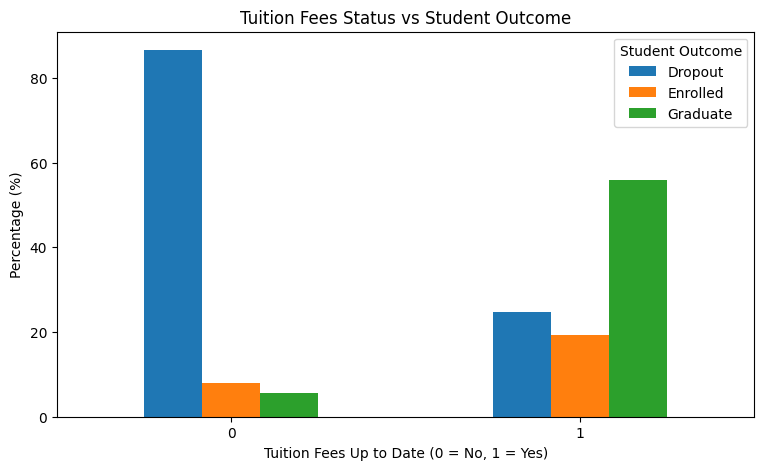

In [11]:
# ==========================================
# EDA Phase 8: Tuition Fees vs Student Outcome
# Objective: Analyze student outcomes based on tuition fee payment status
# ==========================================

tuition_result = pd.crosstab(
    df['Tuition fees up to date'],
    df['Target'],
    normalize='index'
) * 100

print(tuition_result)

tuition_result.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Tuition Fees Status vs Student Outcome')
plt.xlabel('Tuition Fees Up to Date (0 = No, 1 = Yes)')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Student Outcome')
plt.show()

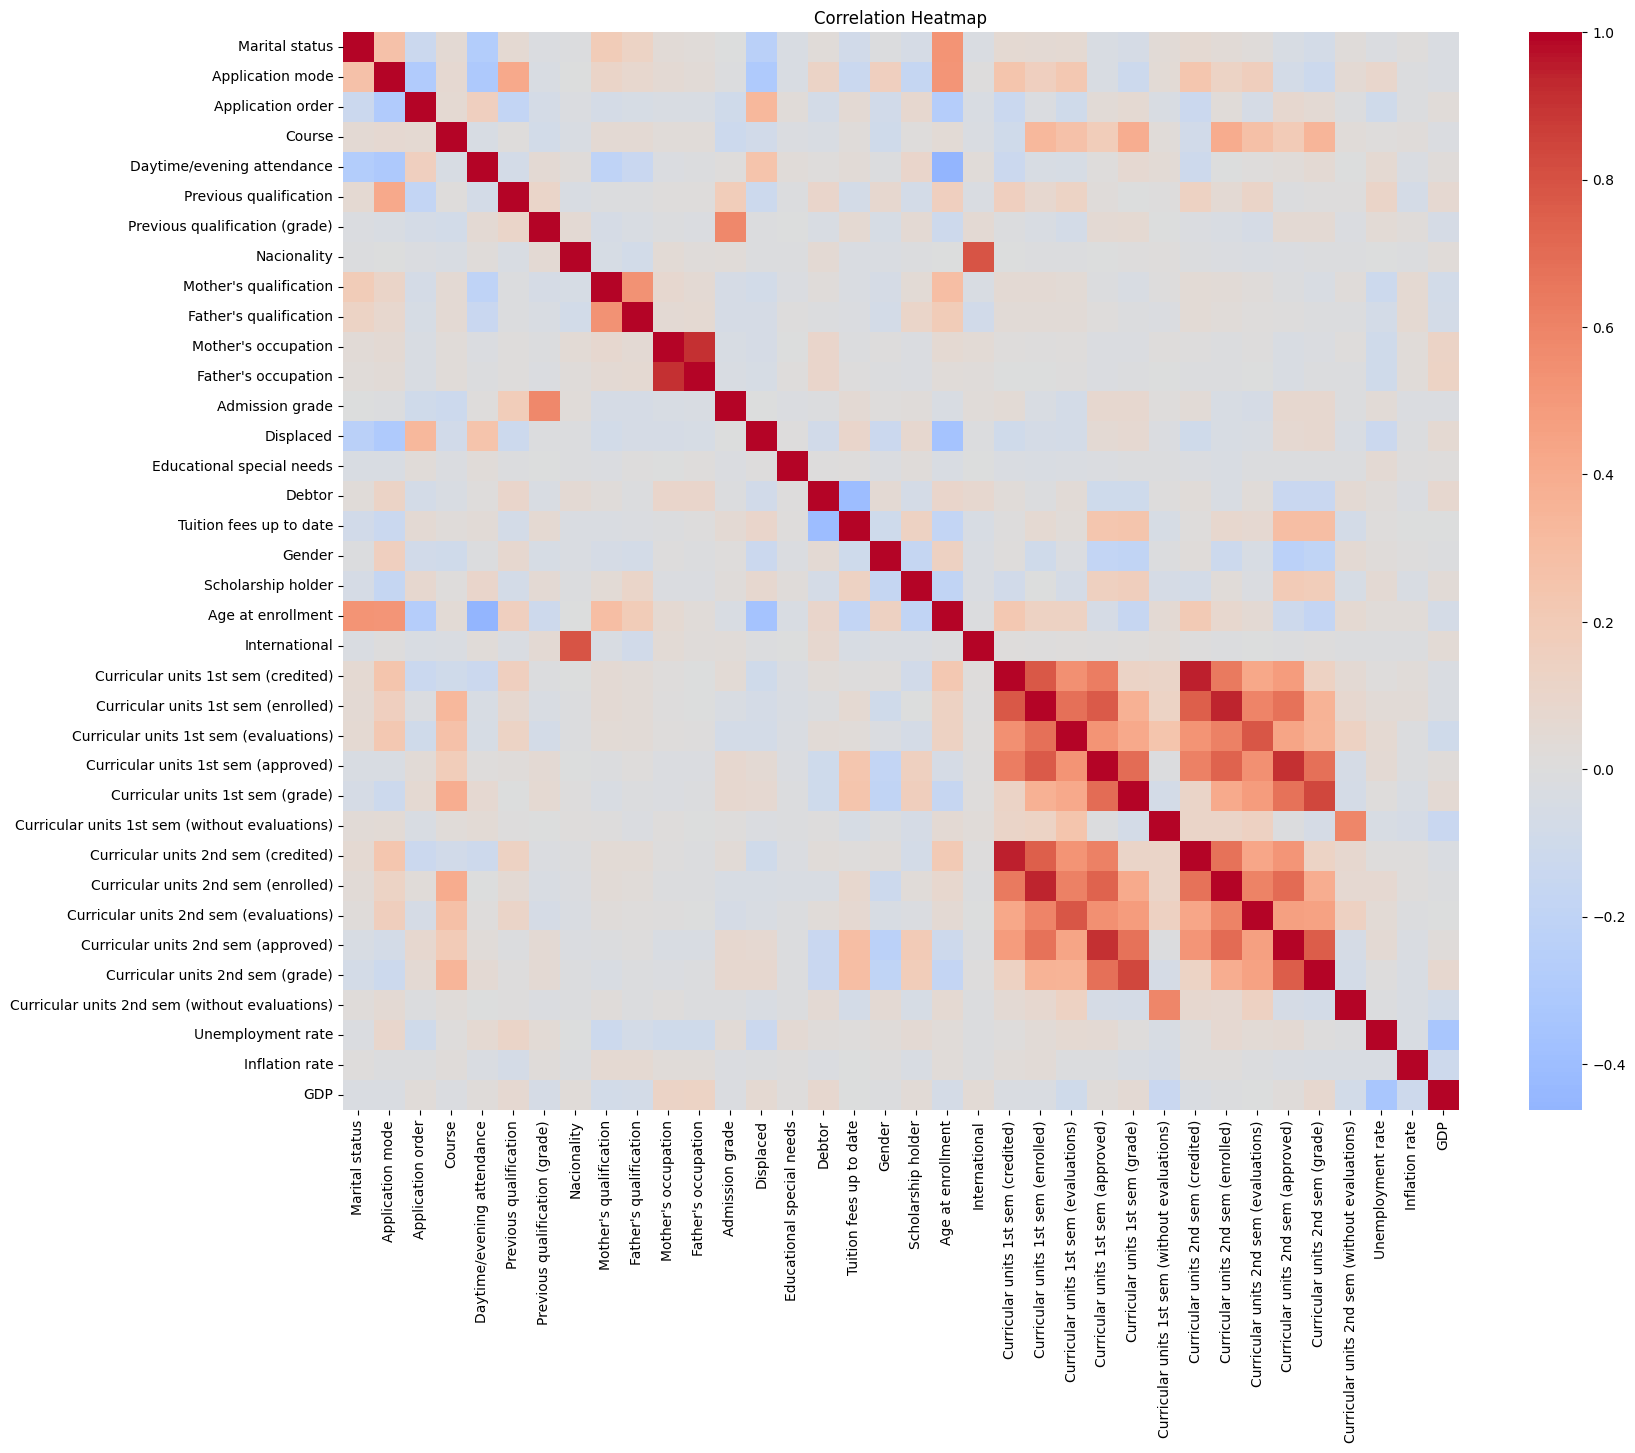

In [12]:
# ==========================================
# EDA Phase 9: Correlation Analysis
# Objective: Identify relationships between numerical features
# ==========================================

numeric_df = df.select_dtypes(include=['int64', 'float64'])

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    annot=False
)

plt.title('Correlation Heatmap')
plt.show()

In [13]:
# ==========================================
# EDA Phase 10: Descriptive Statistics
# Objective: Summarize numerical features
# ==========================================

descriptive_stats = df.describe()

display(descriptive_stats)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


          Curricular units 1st sem (approved)  \
Target                                          
Dropout                              2.551724   
Enrolled                             4.318640   
Graduate                             6.232232   

          Curricular units 2nd sem (approved)  
Target                                         
Dropout                              1.940183  
Enrolled                             4.057935  
Graduate                             6.177003  


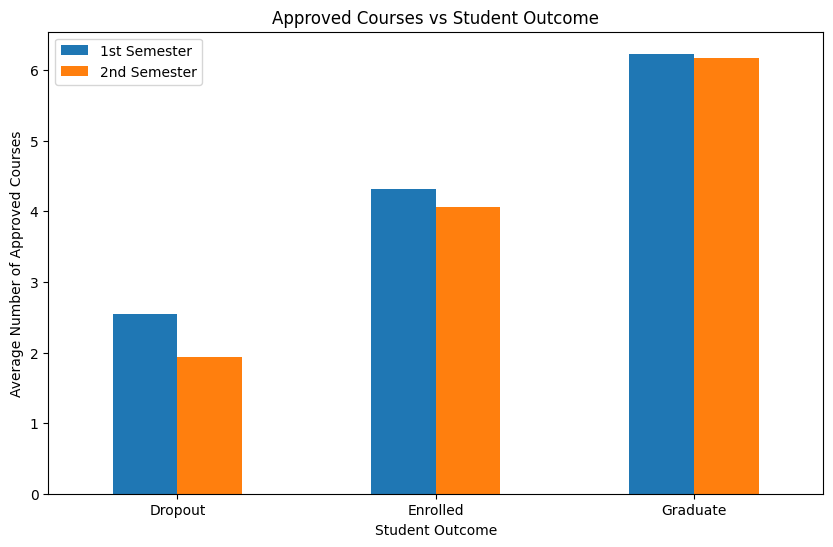

In [14]:
# ==========================================
# EDA Phase 11: Academic Performance Analysis
# Objective: Analyze academic performance across student outcomes
# ==========================================

academic_result = df.groupby('Target')[
    [
        'Curricular units 1st sem (approved)',
        'Curricular units 2nd sem (approved)'
    ]
].mean()

print(academic_result)

academic_result.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Approved Courses vs Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('Average Number of Approved Courses')
plt.xticks(rotation=0)
plt.legend(['1st Semester', '2nd Semester'])
plt.show()

In [15]:
# ==========================================
# EDA Phase 12: EDA Summary
# Objective: Summarize the main EDA findings
# ==========================================

print("========== EDA SUMMARY ==========")

print("\n1. Dataset Information")
print(f"Total Records: {df.shape[0]}")
print(f"Total Features: {df.shape[1] - 2}")

print("\n2. Data Quality")
print(f"Missing Values: {df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")

print("\n3. Target Distribution")
print(df['Target'].value_counts())

print("\n4. Target Percentages")
print(
    (df['Target'].value_counts(normalize=True) * 100).round(2)
)

print("\n========== END OF EDA ==========")

========== EDA SUMMARY ==========

1. Dataset Information
Total Records: 4424
Total Features: 36

2. Data Quality
Missing Values: 0
Duplicate Rows: 0

3. Target Distribution
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

4. Target Percentages
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64

========== END OF EDA ==========
